In [2]:
# conda env at3d_pure_k9
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent

import sys
sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
from src.utils.util import load_sensor_dict, load_config
import numpy as np

In [3]:
savefigs = True
exp_version = 'V10'
EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / exp_version / 'default'
FIGURE_OUT = EXPERIMENT / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

config = load_config(EXPERIMENT / 'config.yml')
misr_obs = load_sensor_dict(config['obs_file'])

## Figure: MISR observation and cloud mask

In [5]:
mo

<xarray.Dataset>
Dimensions:            (stokes_index: 4, npixels: 36864, nrays: 36864)
Coordinates:
  * stokes_index       (stokes_index) object 'I' 'Q' 'U' 'V'
Dimensions without coordinates: npixels, nrays
Data variables: (12/19)
    wavelength         float64 ...
    stokes             (stokes_index) bool True False False False
    cam_x              (npixels) float64 -13.77 -13.49 -13.22 ... 33.87 34.15
    cam_y              (npixels) float64 41.18 41.15 41.13 ... -15.56 -15.58
    cam_z              (npixels) float64 1.4 1.4 1.4 1.4 1.4 ... 1.4 1.4 1.4 1.4
    cam_mu             (npixels) float64 0.3351 0.3351 0.3351 ... 0.3351 0.3351
    ...                 ...
    ray_weight         (nrays) float64 ...
    use_subpixel_rays  bool False
    I                  (nrays) float64 0.03387 0.03776 ... 0.02169 0.02189
    brf                (nrays) float64 ...
    mu0                float64 ...
    SAA                float64 ...
Attributes:
    name:               DF
    wind_correction_u:  0.856
    wind_correction_v:  1.232

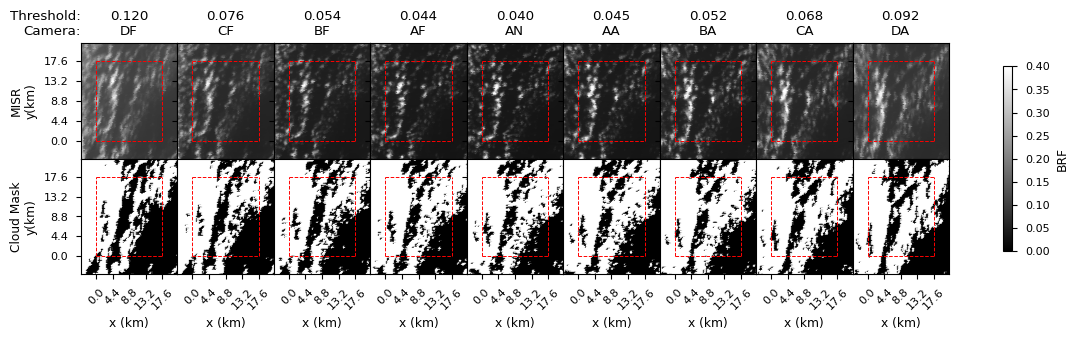

In [7]:
vmin = 0
vmax = 0.4
vrange = 0.18
s = 3
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
ths = [0.120, 0.076, 0.054, 0.044, 0.040, 0.045, 0.052, 0.068, 0.092]

plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(2, 9, figsize=(14, 3), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.0, hspace=0.0)

for i, mo in enumerate(misr_obs['MISR']['sensor_list']):
    c1 = ax[0, i].scatter(
        mo.cam_x.data,
        mo.cam_y.data,
        c = mo.brf.data, #(np.pi * mo.I.data) / mo.mu0,
        s = s,
        cmap = 'gray',
        vmin = vmin,
        vmax = vmax,
        marker = 's'
    )
    c2 = ax[1, i].scatter(
        mo.cam_x.data,
        mo.cam_y.data,
        c = mo.brf.data > ths[i], #((np.pi * mo.I.data) / mo.mu0) > ths[i],
        s = s,
        cmap = 'gray',
        vmin = 0,
        vmax = 1,
        marker = 's'
    )
    title = '{:.3f}\n{}'.format(ths[i], mo.name)
    ax[0, i].set_title(title)
    ax[1, i].set_xlabel('x (km)')
plt.colorbar(c1, ax=ax[:, :], label='BRF', shrink=0.8)
ax[0, 0].set_ylabel('MISR\ny(km)')
ax[1, 0].set_ylabel('Cloud Mask\ny(km)')

ls = '--'
lw = 0.7
for a in ax.flat:
    a.plot([0, 0], [0, 17.6], c='r', ls=ls, lw=lw)
    a.plot([0, 17.6], [0, 0], c='r', ls=ls, lw=lw)
    a.plot([17.6, 17.6], [0, 17.6], c='r', ls=ls, lw=lw)
    a.plot([0, 17.6], [17.6, 17.6], c='r', ls=ls, lw=lw)
    a.set_xticks(ticks)
    a.set_xticklabels(ticks, rotation=45)
    a.set_yticks(ticks)
    a.set_xlim([-4, 17.6+4])
    a.set_ylim([-4, 17.6+4])

ax[0,0].set_title('Threshold:\nCamera:', loc='right', x=0)

if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'MISR_obs_and_CM.png',
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )